# SEMAS: Electronic Service Manual Recognition & Navigation System

### 1. Environment & Execution Hardware Check

In [1]:
from pathlib import Path
import os
import sys
import cv2
import torch

# Switch to project root if running from a nested directory
if not (Path.cwd() / "src").is_dir() and (Path.cwd().parent / "src").is_dir():
    %cd ..

# Ensure active virtual environment binaries are prioritized in PATH
venv_bin = str(Path(sys.executable).parent)
if venv_bin not in os.environ["PATH"]:
    os.environ["PATH"] = venv_bin + ":" + os.environ["PATH"]

# Ensure current working directory is at root of sys.path
cwd = str(Path.cwd())
if cwd not in sys.path:
    sys.path.insert(0, cwd)

# Inspect device and environment metadata
cuda_available = torch.cuda.is_available()
gpu_device_name = torch.cuda.get_device_name(0) if cuda_available else "CPU"

print("=== SEMAS ENVIRONMENT INFO ===")
print("[INFO] Working Directory : " + cwd)
print("[INFO] Python Binary     : " + sys.executable)
print("[INFO] Python Version    : " + sys.version.split()[0])
print("[INFO] PyTorch Version   : " + str(torch.__version__))
print("[INFO] CUDA Available    : " + str(cuda_available))
print("[INFO] GPU Device        : " + gpu_device_name)
print("[INFO] OpenCV Version    : " + str(cv2.__version__))
print("==============================")

/home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS
=== SEMAS ENVIRONMENT INFO ===
[INFO] Working Directory : /home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS
[INFO] Python Binary     : /home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/.venv/bin/python
[INFO] Python Version    : 3.10.12
[INFO] PyTorch Version   : 2.14.1+cu130
[INFO] CUDA Available    : True
[INFO] GPU Device        : NVIDIA GeForce RTX 4080 Laptop GPU
[INFO] OpenCV Version    : 4.10.0


/home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/.venv/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


### 2. Data Preparation and 300 DPI Image Extraction (`src/extract_manuals_pages.py`)

In [2]:
%run src/extract_manuals_pages.py

[INFO] Created directory structure at: /home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/data/extracted_manuals

[INFO] Processing: Acoustic_Control_450_Lead_Bass_Guitar_Amplifier_Service Manual_1974.pdf (Short name: Acoustic_450)
[INFO] Using cached page: Acoustic_450_page_014.png
[INFO] Using cached page: Acoustic_450_page_015.png
[INFO] Using cached page: Acoustic_450_page_016.png
[INFO] Using cached page: Acoustic_450_page_017.png
[INFO] Using cached page: Acoustic_450_page_006.png
[INFO] Using cached page: Acoustic_450_page_007.png
[INFO] Using cached page: Acoustic_450_page_008.png
[INFO] Using cached page: Acoustic_450_page_009.png
[INFO] Using cached page: Acoustic_450_page_010.png
[INFO] Using cached page: Acoustic_450_page_011.png
[INFO] Using cached page: Acoustic_450_page_012.png
[INFO] Using cached page: Acoustic_450_page_013.png

[INFO] Processing: Akai_AM-M630_AM-M830_Digital_Integrated_Amplifier_Service_Manual.pdf (Short name: Akai_AM_M6

### 3. Training a YOLO Component Detection Model

In [3]:
# train_yolo.py
# YOLO Training Script
from __future__ import annotations
from ultralytics import YOLO

def train_yolo_model(weights_path, data_yaml):
    """ Train YOLO model on Roboflow electronic component dataset.

    Args:
      - weights_path (str) : Pretrained weights file path.
      - data_yaml (str) : Path to Roboflow dataset yaml configuration.
    Returns: None.
    """
    model_name = "semas_yolo26m_exp"
    if (model_name in os.listdir("runs/detect")):
        print("[INFO] Model '" + model_name + "' already exists. Skipping training.")
        return
    model = YOLO(weights_path)
    model.train(
        data=data_yaml,
        epochs=300,
        imgsz=1280,
        batch=2,
        mosaic=0.0,
        name=model_name,
        max_det=1000,
        save=True,
    )

if __name__ == "__main__":
    weights_path = "yolo26m.pt"
    data_yaml = "./data/Roboflow/datasets/SEMAS_Components_Detection.v6-81_images_compo-spec.yolo26/data.yaml"
    train_yolo_model(weights_path, data_yaml)

[INFO] Model 'semas_yolo26m_exp' already exists. Skipping training.


In [4]:
#predict_test.py
# Prediction Test Script

from __future__ import annotations
from ultralytics import YOLO

def run_prediction(model_path, img_path):
    """ Run YOLO component detection on a target image and print detected box count.
    Args:
      - model_path (str) : Path to trained YOLO model weights.
      - img_path (str) : Target image path.
    Returns: None.
    """
    model = YOLO(model_path)
    results = model.predict(
        source=img_path,
        save=False,
        conf=0.2,
        imgsz=1280,
        max_det=1000,
    )

    for r in results:
        print("Number of components found: " + str(len(r.boxes)))

if __name__ == "__main__":
    model_path = "runs/detect/semas_yolo26m_exp/weights/best.pt"
    img_path = (
        "./data/extracted_manuals/Sony-TA-1630-Service-Manual/schematic/Sony_TA_1630_page_006.png"
    )
    run_prediction(model_path, img_path)



image 1/1 /home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/data/extracted_manuals/Sony-TA-1630-Service-Manual/schematic/Sony_TA_1630_page_006.png: 928x1280 144 compo_names, 110 spec_values, 16.7ms
Speed: 26.9ms preprocess, 16.7ms inference, 10.1ms postprocess per image at shape (1, 3, 928, 1280)
Number of components found: 254


In [ ]:
from __future__ import annotations
import sys
import re
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir.parent if not (current_dir / "src").exists() else current_dir
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import numpy as np
import torch
from IPython.display import Image, display
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

from ocr_engine import get_ocr_engine, read_text_with_orthogonal_rotations


def run_detection_and_ocr(img_path, model_path, engine_name, conf_thresh, slice_height, slice_width, overlap_ratio, pad, output_vis):
    """ Run SAHI sliced inference with YOLO detector and recognize RefDes labels via OCR.

    Args:
      - img_path : Path to target schematic or PCB scan image.
      - model_path : Path to trained YOLO weights file.
      - engine_name: OCR engine to use ('paddleocr', 'easyocr', etc.).
      - conf_thresh : Detection confidence threshold.
      - slice_height : Height of each SAHI slice window.
      - slice_width : Width of each SAHI slice window.
      - overlap_ratio : Overlap ratio between adjacent slice windows.
      - pad : Extra padding around bounding box crops.
      - output_vis: Optional path to save the annotated visualization image.
    Returns: List of dictionaries containing text, ocr_confidence, det_confidence, and bbox.
    """
    img_path = Path(img_path)
    model_path = Path(model_path)

    if not img_path.exists():
        raise FileNotFoundError("Target image scan not found: " + str(img_path))
    if not model_path.exists():
        raise FileNotFoundError("YOLO model weights not found: " + str(model_path))

    # Determine execution device
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    print("[INFO] Using device for SAHI inference: " + device)

    # Initialize OCR engine
    ocr_model = get_ocr_engine(engine_name, True, "en")

    # Read input image scan
    img = cv2.imread(str(img_path))
    if img is None:
        raise ValueError("Failed to load image at: " + str(img_path))
    output_img = img.copy()
    h_img, w_img, _ = img.shape
    print("[INFO] Loaded input image: " + img_path.name + " (shape: " + str(w_img) + "x" + str(h_img) + ")")

    # Initialize SAHI AutoDetectionModel wrapper for YOLO
    print("[INFO] Loading YOLO detector via SAHI from: " + str(model_path))
    detection_model = AutoDetectionModel.from_pretrained(
        model_type="yolov8",
        model_path=str(model_path),
        confidence_threshold=conf_thresh,
        device=device,
    )

    # Execute SAHI sliced prediction
    print("[INFO] Executing SAHI sliced prediction (slice: " + str(slice_width) + "x" + str(slice_height) + ", overlap: " + str(overlap_ratio) + ")...")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    sliced_result = get_sliced_prediction(
        img_rgb,
        detection_model,
        slice_height=slice_height,
        slice_width=slice_width,
        overlap_height_ratio=overlap_ratio,
        overlap_width_ratio=overlap_ratio,
        postprocess_type="NMS",
        postprocess_match_metric="IOU",
        postprocess_match_threshold=0.4,
        postprocess_class_agnostic=False,
        batch_size=4,
        verbose=0,
    )

    total_candidates = len(sliced_result.object_prediction_list)
    print("[INFO] SAHI detected " + str(total_candidates) + " candidate component boxes.")
    print("[INFO] Running OCR with engine: " + engine_name.upper() + "...")

    results = []

    for obj in sliced_result.object_prediction_list:
        cat_name = obj.category.name if obj.category else ""
        cat_id = obj.category.id if obj.category else -1

        # Semantic Rescue: Candidate must be compo_name or spec_value
        is_compo = (cat_name == "compo_name" or cat_id == 0)
        is_spec = (cat_name == "spec_value" or cat_id == 1)
        if not is_compo and not is_spec:
            continue

        bbox = obj.bbox
        det_conf = float(obj.score.value)
        if not (np.isfinite(bbox.minx) and np.isfinite(bbox.miny) and np.isfinite(bbox.maxx) and np.isfinite(bbox.maxy)):
            continue

        # Clamp detection coordinates to image frame
        x1_det = max(0, min(w_img, int(round(bbox.minx))))
        y1_det = max(0, min(h_img, int(round(bbox.miny))))
        x2_det = max(0, min(w_img, int(round(bbox.maxx))))
        y2_det = max(0, min(h_img, int(round(bbox.maxy))))

        if (x2_det - x1_det) < 4 or (y2_det - y1_det) < 4:
            continue

        # Derive safe crop coordinates with padding
        x1_crop = max(0, x1_det - pad)
        y1_crop = max(0, y1_det - pad)
        x2_crop = min(w_img, x2_det + pad)
        y2_crop = min(h_img, y2_det + pad)

        crop = img[y1_crop:y2_crop, x1_crop:x2_crop]
        if crop.size == 0:
            continue

        # Sweep orthogonal rotations (0, 90, 180, 270 deg) with semantic ranking
        text, ocr_conf, best_angle = read_text_with_orthogonal_rotations(crop, ocr_model, None)

        if text:
            if is_spec:
                clean_ref = re.sub(r"[^A-Za-z0-9]", "", text.strip()).upper()
                if not re.match(r"^[A-Z]{1,3}\d{1,4}[A-Z]?$", clean_ref):
                    continue

            record = {
                "text": text,
                "ocr_confidence": round(ocr_conf, 2),
                "det_confidence": round(det_conf, 2),
                "bbox": [x1_det, y1_det, x2_det, y2_det],
                "rotation_deg": best_angle,
            }
            results.append(record)
            print("[" + engine_name.upper() + "] Found: " + text + " (OCR conf: " + str(ocr_conf) + ", Det conf: " + str(det_conf) + ", Angle: " + str(best_angle) + " deg) at [" + str(x1_det) + ", " + str(y1_det) + ", " + str(x2_det) + ", " + str(y2_det) + "]")

            # Annotate visualization
            cv2.rectangle(output_img, (x1_det, y1_det), (x2_det, y2_det), (0, 255, 0), 2)
            label = text + " (" + str(round(ocr_conf, 2)) + ")"
            cv2.putText(
                output_img,
                label,
                (x1_det, max(14, y1_det - 4)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (0, 0, 255),
                1,
                cv2.LINE_AA,
            )

    # Save visualization image
    if output_vis:
        out_path = Path(output_vis)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        print("[INFO] Saved visualization: " + str(out_path.resolve()))

    print("\nSummary:")
    print("- Total candidate components detected: " + str(total_candidates))
    print("- Components successfully recognized by OCR: " + str(len(results)))

    return results

if __name__ == "__main__":
    img_path = "./data/extracted_manuals/Sony-TA-1630-Service-Manual/schematic/Sony_TA_1630_page_006.png"
    model_path = "./runs/detect/semas_yolo26m_exp/weights/best.pt"
    engine_name = "paddleocr"
    conf_thresh = 0.4
    pad = 5
    slice_height = 1024
    slice_width = 1024
    overlap_ratio = 0.25
    output_vis = "detected_components_vis.png"

    recognized_components = run_detection_and_ocr(
        img_path,
        model_path,
        engine_name,
        conf_thresh,
        slice_height,
        slice_width,
        overlap_ratio,
        pad,
        output_vis,
    )


[INFO] Using device for SAHI inference: cuda:0
[INFO] Loaded input image: Sony_TA_1630_page_006.png (shape: 4961x3508)
[INFO] Loading YOLO detector via SAHI from: runs/detect/semas_yolo26m_exp/weights/best.pt
[INFO] Executing SAHI sliced prediction (slice: 1024x1024, overlap: 0.25)...
[INFO] SAHI detected 142 candidate component boxes.
[INFO] Running OCR with engine: PADDLEOCR...


/home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/felixilars/Documents/INSA-INFO-Vault/01-Semestre-5/Etude Pratique/Code/SEMAS/.venv/lib/python3.10/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/felixilars/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None,

[PADDLEOCR] Found: C103 (OCR conf: 0.9726582765579224, Det conf: 0.7667249441146851, Angle: 0 deg) at [888, 1134, 952, 1169]
[PADDLEOCR] Found: C133 (OCR conf: 0.9903957843780518, Det conf: 0.752768337726593, Angle: 0 deg) at [2539, 960, 2606, 994]
[PADDLEOCR] Found: S2-1 (OCR conf: 0.9988773465156555, Det conf: 0.7427474856376648, Angle: 0 deg) at [1602, 898, 1663, 927]
[PADDLEOCR] Found: C130 (OCR conf: 0.9833595156669617, Det conf: 0.736886203289032, Angle: 0 deg) at [2276, 888, 2342, 920]
[PADDLEOCR] Found: S5 (OCR conf: 0.9994796514511108, Det conf: 0.7324679493904114, Angle: 0 deg) at [2889, 2881, 2935, 2914]
[PADDLEOCR] Found: Q206 (OCR conf: 0.9998877048492432, Det conf: 0.7290963530540466, Angle: 0 deg) at [3279, 2457, 3376, 2503]
[PADDLEOCR] Found: PT401 (OCR conf: 0.9976037740707397, Det conf: 0.722468912601471, Angle: 0 deg) at [2435, 2814, 2505, 2846]
[PADDLEOCR] Found: CNP401 (OCR conf: 0.9955148100852966, Det conf: 0.7206436991691589, Angle: 0 deg) at [1892, 2977, 1977, 

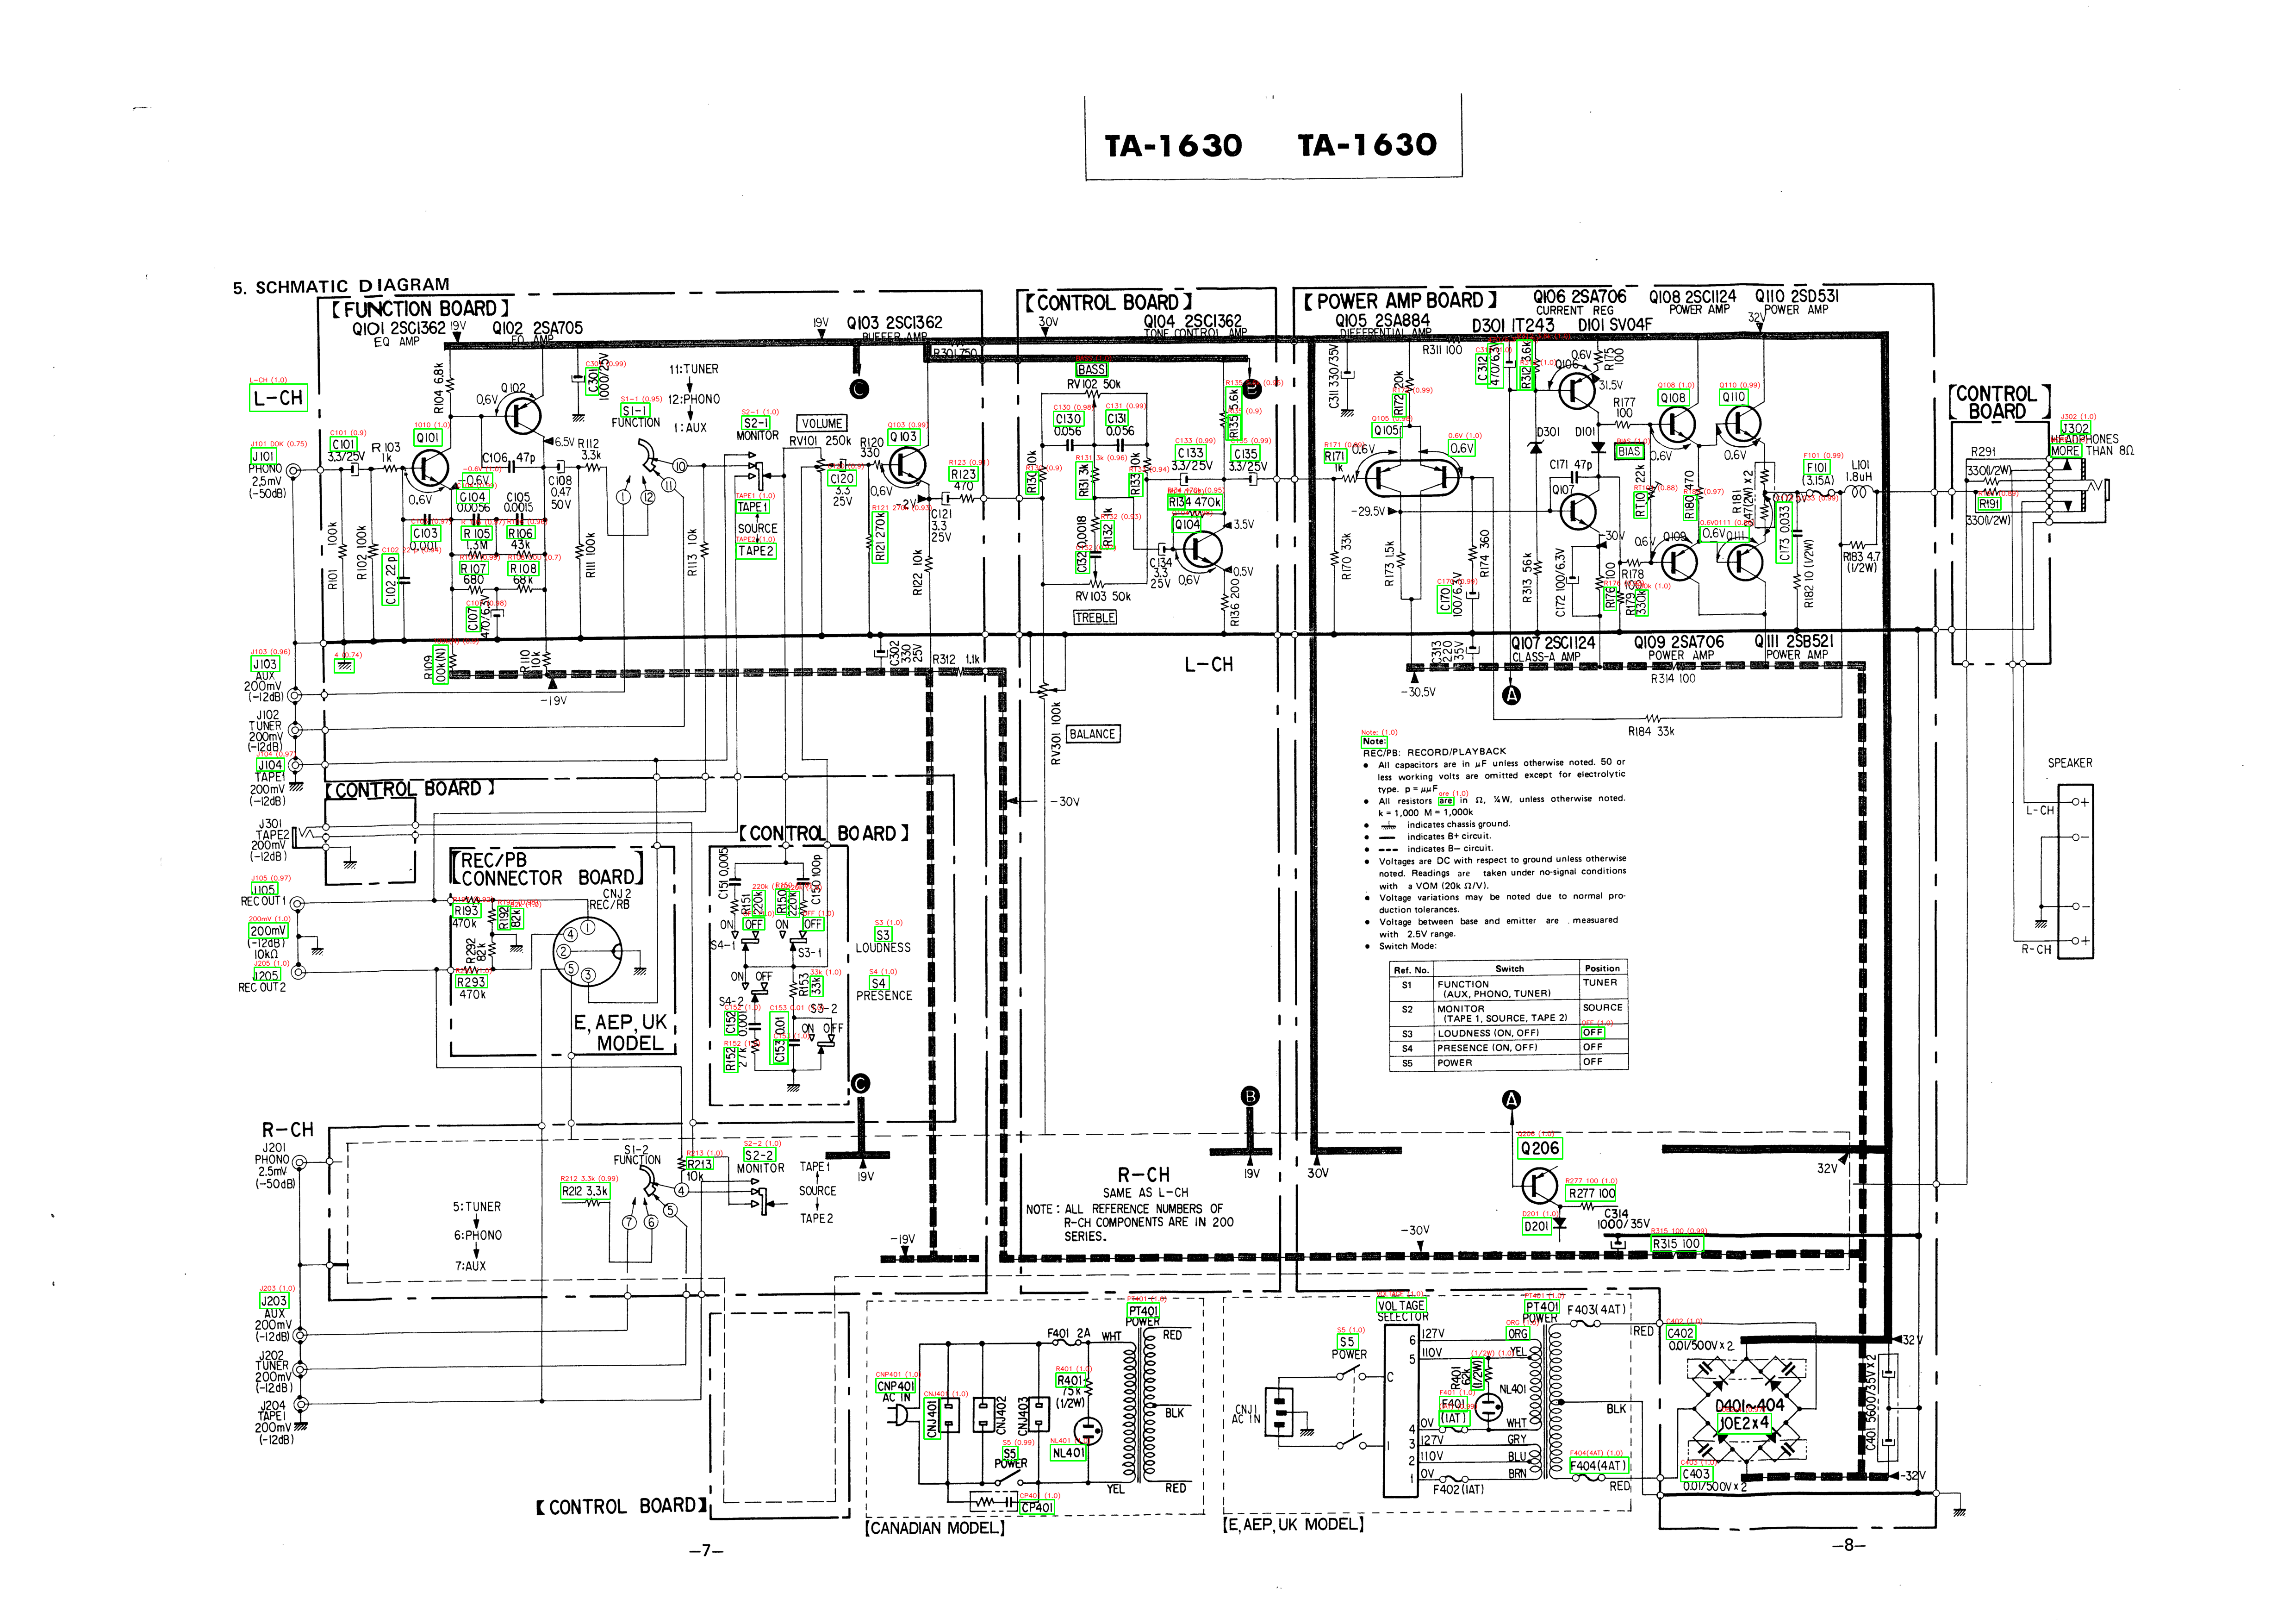

In [6]:
# show detected_components_vis.png

from IPython.display import Image

Image("detected_components_vis.png")